Dataset loaded successfully!
Rows: 780
Columns: 11

First 5 records:
   Store  Dept       Date  Weekly_Sales  IsHoliday  Temperature  Fuel_Price  \
0      1     1   1/3/2025      23761.61          1        18.46        3.37   
1      1     1  1/10/2025      26707.85          1        17.53        3.45   
2      1     1  1/17/2025      18547.62          0        18.70        3.38   
3      1     1  1/24/2025      18871.23          0        16.98        3.55   
4      1     1  1/31/2025      19024.36          0        18.62        3.48   

   Markdown     CPI  Unemployment    Size  
0   3227.01  250.47          5.25  120000  
1   6792.78  250.44          5.17  120000  
2   1137.00  249.52          5.23  120000  
3    840.10  249.79          5.21  120000  
4    666.83  249.80          5.32  120000  

Missing values:
Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
Temperature     0
Fuel_Price      0
Markdown        0
CPI             0
Unemployment 

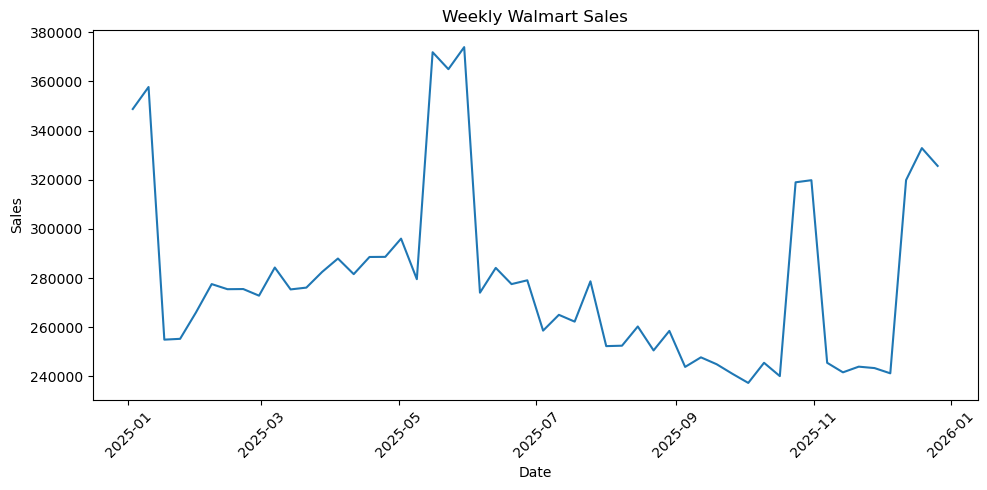


Training records: 624
Testing records: 156

Training model...
Model training completed!

MODEL RESULTS
MAE  : 1567.52
RMSE : 1972.68
R2   : 0.6589


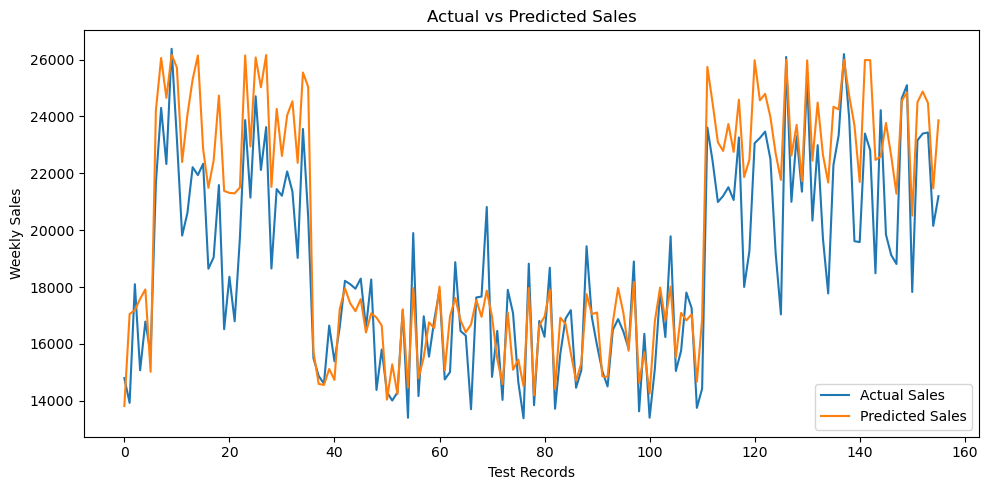


Feature Importance:
IsHoliday       0.386711
Size            0.290451
Markdown        0.112059
Temperature     0.109206
CPI             0.023576
Fuel_Price      0.019789
Unemployment    0.018895
Week            0.018383
Store           0.009464
Dept            0.007186
Month           0.004280
Year            0.000000
Promotion       0.000000
dtype: float64


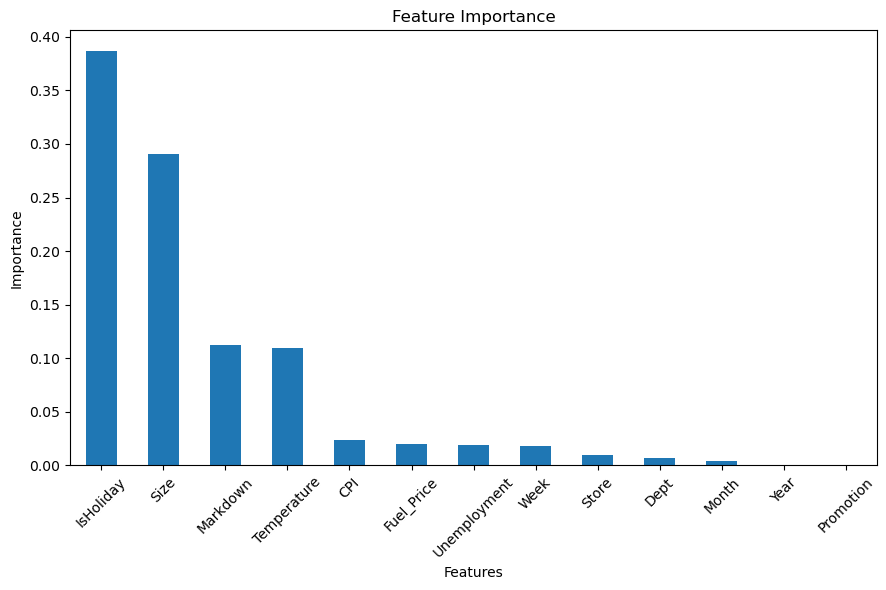


PROJECT COMPLETED SUCCESSFULLY!


In [1]:
# WALMART SALES PREDICTION
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# 1. LOAD DATASET
df = pd.read_csv("D:\studies\ml cs.csv")
print("Dataset loaded successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("\nFirst 5 records:")
print(df.head())
# 2. CHECK DATA
print("\nMissing values:")
print(df.isnull().sum())
# 3. DATA PREPROCESSING
df["Date"] = pd.to_datetime(df["Date"])
# Create useful date features
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Week"] = df["Date"].dt.isocalendar().week.astype(int)
# Create promotion column
df["Promotion"] = (df["Markdown"] > 0).astype(int)
# Remove missing sales values
df = df.dropna(subset=["Weekly_Sales"])
print("\nData preprocessing completed!")
# 4. SALES TREND GRAPH
sales = df.groupby("Date")["Weekly_Sales"].sum()
plt.figure(figsize=(10, 5))
plt.plot(sales.index, sales.values)
plt.title("Weekly Walmart Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
# 5. SELECT FEATURES
features = [
    "Store",
    "Dept",
    "IsHoliday",
    "Temperature",
    "Fuel_Price",
    "Markdown",
    "CPI",
    "Unemployment",
    "Size",
    "Year",
    "Month",
    "Week",
    "Promotion"
]
X = df[features]
y = df["Weekly_Sales"]
# 6. SORT DATA BY DATE
df = df.sort_values("Date")
X = df[features]
y = df["Weekly_Sales"]
# 7. SPLIT DATA
split = int(len(df) * 0.8)
X_train = X.iloc[:split]
X_test = X.iloc[split:]
y_train = y.iloc[:split]
y_test = y.iloc[split:]
print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))
# 8. RANDOM FOREST MODEL
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
print("\nTraining model...")
model.fit(X_train, y_train)
print("Model training completed!")
# 9. PREDICTION
prediction = model.predict(X_test)
# 10. MODEL EVALUATION
mae = mean_absolute_error(y_test, prediction)
rmse = np.sqrt(
    mean_squared_error(y_test, prediction)
)
r2 = r2_score(y_test, prediction)
print("\n==============================")
print("MODEL RESULTS")
print("==============================")
print("MAE  :", round(mae, 2))
print("RMSE :", round(rmse, 2))
print("R2   :", round(r2, 4))
# 11. ACTUAL VS PREDICTED
plt.figure(figsize=(10, 5))
plt.plot(
    y_test.values,
    label="Actual Sales"
)
plt.plot(
    prediction,
    label="Predicted Sales"
)
plt.title("Actual vs Predicted Sales")
plt.xlabel("Test Records")
plt.ylabel("Weekly Sales")
plt.legend()
plt.tight_layout()
plt.show()
# 12. FEATURE IMPORTANCE
importance = pd.Series(
    model.feature_importances_,
    index=features
)

importance = importance.sort_values(
    ascending=False
)
print("\nFeature Importance:")
print(importance)
plt.figure(figsize=(9, 6))
importance.plot(kind="bar")
plt.title("Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
# 13. FINAL MESSAGE
print("\n================================")
print("PROJECT COMPLETED SUCCESSFULLY!")
print("================================")